In [34]:
# !pip install pandas
# !pip install numpy
# !pip install tensorflow
# !pip install kernel
# !pip install keras

In [35]:
import pandas as pd
import numpy as np
import tensorflow as tf
import pickle
import re
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Dense, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau


In [36]:
from sklearn.model_selection import train_test_split

In [37]:
with open('/content/Harry_Potter_all_char_separated.txt', 'rt') as file:
    data = file.read()

print(len(data), "characters")
print(data[:500])

6515219 characters
Chapter : THE BOY WHO LIVED .| Mr and Mrs Dursley , of number four , Privet Drive , were proud to say that they were perfectly normal , thank you very much .| They were the last people you’d expect to be involved in anything strange or mysterious , because they just didn’t hold with such nonsense .| Mr Dursley was the director of a firm called Grunnings , which made drills .| He was a big , beefy man with hardly any neck , although he did have a very large mustache .| Mrs Dursley was thin and bl


In [38]:
corpus = data.replace('\n', ' ').split('|')

corpus = [s.strip() for s in corpus if s.strip()]

print(len(corpus), ' raw sentences')

79730  raw sentences


In [39]:
df = pd.DataFrame({'text': corpus})

In [40]:
df.head(3)

,text
0,Chapter : THE BOY WHO LIVED .
1,"Mr and Mrs Dursley , of number four , Privet D..."
2,They were the last people you’d expect to be i...


In [41]:
df = df[~df['text'].str.startswith('Chapter')].reset_index(drop=True)

In [42]:
df.head(2)

,text
0,"Mr and Mrs Dursley , of number four , Privet D..."
1,They were the last people you’d expect to be i...


In [43]:
def _join_abbrev(m):
    return re.sub(r"[\s.]", "", m.group(0))

def clean_text(t):
    t = t.lower()
    t = t.replace('’', "'").replace('‘', "'")
    t = t.replace('“', '').replace('”', '').replace('"', '')
    t = re.sub(r"\b[a-z](?: \. [a-z])+\b", _join_abbrev, t)   # "o . w . l . s" -> "owls"
    t = re.sub(r"(?<=[a-z0-9])\s*'\s*s\b", "'s", t)           # "hermione ' s"  -> "hermione's"
    t = re.sub(r"[^a-z0-9'\s]", ' ', t)                       # drop punctuation, keep apostrophes
    t = re.sub(r"(?<![a-z0-9])'|'(?![a-z0-9])", ' ', t)       # drop apostrophes used as quote marks
    t = re.sub(r'\s+', ' ', t).strip()
    return t

In [44]:
df['clean'] = df['text'].apply(clean_text)

In [45]:
df['n_words'] = df['clean'].str.split().str.len()

In [46]:
df['n_words'].shape

(79564,)

In [47]:
df.shape

(79564, 3)

In [48]:
df = df[df['n_words'] >=3].reset_index(drop=True)

In [49]:
df.shape

(73413, 3)

In [50]:
import json
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Input, SpatialDropout1D
from tensorflow.keras.regularizers import l2

split first (avoids leakage)

In [51]:
train_sents, val_sents = train_test_split(
    df['clean'], test_size=0.1, random_state=42
)

tokenizer on training sentences

In [52]:
MAX_VOCAB = 8000
tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token='<OOV>')
tokenizer.fit_on_texts(train_sents)

In [53]:
total_words = min(MAX_VOCAB, len(tokenizer.word_index) + 1)   # +1 for padding index 0
OOV_INDEX = tokenizer.word_index['<OOV>']

sequence length from the data

In [54]:
MAX_LEN = int(min(30, max(10, df['n_words'].quantile(0.95))))
INPUT_LEN = MAX_LEN - 1

In [55]:
# n=gram pairs

def make_xy(sentences, max_len=MAX_LEN):
    seqs = []
    for s in sentences:
        toks = tokenizer.texts_to_sequences([s])[0]
        for i in range(1, len(toks)):
            seqs.append(toks[:i + 1])
    padded = pad_sequences(seqs, maxlen=max_len, padding='pre', truncating='pre')
    return padded[:, :-1], padded[:, -1]

X_train, y_train = make_xy(train_sents)
X_val, y_val = make_xy(val_sents)

In [56]:
# model and compile

model = Sequential([
    Input(shape=(INPUT_LEN,)),
    Embedding(total_words, 100),
    SpatialDropout1D(0.3),
    LSTM(192, return_sequences=True, dropout=0.3),   # True: feeds the next LSTM
    LSTM(192, dropout=0.3),                          # last LSTM returns 2D
    Dropout(0.4),
    Dense(total_words, activation='softmax', kernel_regularizer=l2(1e-6)),
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(5e-4),
    metrics=[
        'accuracy',
        tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top5'),
    ],
)

In [57]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 29, 100)        │       800,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 29, 100)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 29, 192)        │       225,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 192)            │       295,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8000)           │     1,544,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,864,704 (10.93 MB)

 Trainable params: 2,864,704 (10.93 MB)

 Non-trainable params: 0 (0.00 B)

In [58]:
# callbacks

callbacks = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, min_lr=1e-5),
    ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True),
]

In [59]:
print(tf.config.list_physical_devices('GPU'))   # should list one GPU

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [60]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=256,
    callbacks=callbacks,
)

Epoch 1/30
3541/3541 ━━━━━━━━━━━━━━━━━━━━ 94s 25ms/step - accuracy: 0.0685 - loss: 6.3557 - top5: 0.1783 - val_accuracy: 0.0953 - val_loss: 5.9709 - val_top5: 0.2204 - learning_rate: 5.0000e-04
Epoch 2/30
3541/3541 ━━━━━━━━━━━━━━━━━━━━ 88s 25ms/step - accuracy: 0.1045 - loss: 5.8660 - top5: 0.2387 - val_accuracy: 0.1233 - val_loss: 5.6039 - val_top5: 0.2765 - learning_rate: 5.0000e-04
Epoch 3/30
3541/3541 ━━━━━━━━━━━━━━━━━━━━ 89s 25ms/step - accuracy: 0.1195 - loss: 5.6123 - top5: 0.2716 - val_accuracy: 0.1337 - val_loss: 5.4207 - val_top5: 0.2980 - learning_rate: 5.0000e-04
Epoch 4/30
3541/3541 ━━━━━━━━━━━━━━━━━━━━ 89s 25ms/step - accuracy: 0.1276 - loss: 5.4703 - top5: 0.2869 - val_accuracy: 0.1420 - val_loss: 5.3089 - val_top5: 0.3132 - learning_rate: 5.0000e-04
Epoch 5/30
3541/3541 ━━━━━━━━━━━━━━━━━━━━ 90s 25ms/step - accuracy: 0.1336 - loss: 5.3818 - top5: 0.2978 - val_accuracy: 0.1478 - val_loss: 5.2386 - val_top5: 0.3223 - learning_rate: 5.0000e-04
Epoch 6/30
3541/3541 ━━━━━━━━━

Epoch 31/100
3541/3541 ━━━━━━━━━━━━━━━━━━━━ 87s 24ms/step - accuracy: 0.1686 - loss: 5.0321 - top5: 0.3543 - val_accuracy: 0.1831 - val_loss: 5.0028 - val_top5: 0.3745 - learning_rate: 6.2500e-05
Epoch 32/100
3541/3541 ━━━━━━━━━━━━━━━━━━━━ 86s 24ms/step - accuracy: 0.1682 - loss: 5.0313 - top5: 0.3542 - val_accuracy: 0.1832 - val_loss: 5.0036 - val_top5: 0.3744 - learning_rate: 6.2500e-05
Epoch 33/100
3541/3541 ━━━━━━━━━━━━━━━━━━━━ 86s 24ms/step - accuracy: 0.1687 - loss: 5.0263 - top5: 0.3548 - val_accuracy: 0.1836 - val_loss: 5.0025 - val_top5: 0.3745 - learning_rate: 3.1250e-05
Epoch 34/100
3541/3541 ━━━━━━━━━━━━━━━━━━━━ 86s 24ms/step - accuracy: 0.1690 - loss: 5.0274 - top5: 0.3550 - val_accuracy: 0.1834 - val_loss: 5.0030 - val_top5: 0.3747 - learning_rate: 3.1250e-05
Epoch 35/100
3541/3541 ━━━━━━━━━━━━━━━━━━━━ 86s 24ms/step - accuracy: 0.1689 - loss: 5.0261 - top5: 0.3553 - val_accuracy: 0.1832 - val_loss: 5.0026 - val_top5: 0.3746 - learning_rate: 1.5625e-05
Epoch 36/100
3541/35

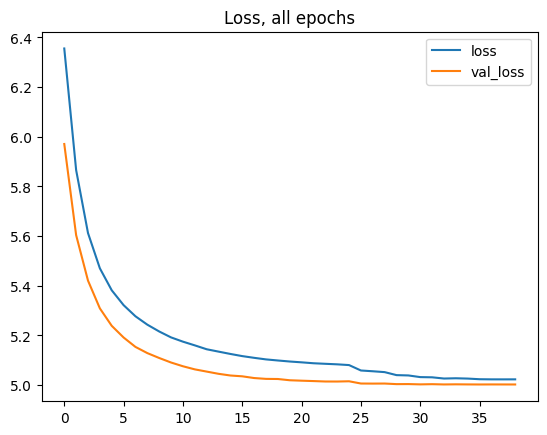

In [69]:
hist1 = history.history                       # save the first run's log

history2 = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    initial_epoch=len(hist1['loss']),         # continue numbering from where it stopped
    epochs=100,                               # the final epoch number, not 100 more
    batch_size=256,
    callbacks=callbacks,
)

# stitch both runs into one curve
full = {k: hist1[k] + history2.history[k] for k in hist1}
pd.DataFrame(full)[['loss', 'val_loss']].plot(title='Loss, all epochs')
plt.show()

# TESTS

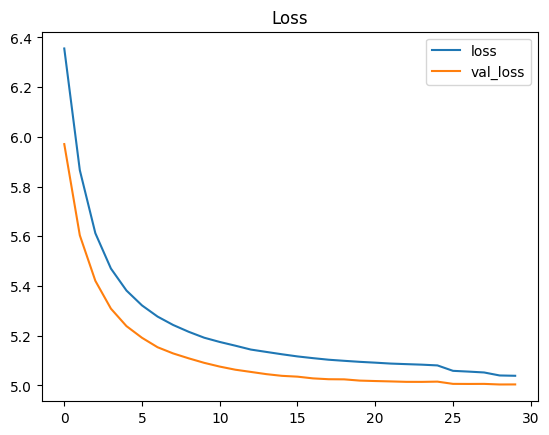

In [70]:
pd.DataFrame(history.history)[['loss', 'val_loss']].plot(title='Loss')
plt.show()

In [76]:
val_loss, val_acc, val_top5 = model.evaluate(X_val, y_val, batch_size=512, verbose=0)
best_epoch = int(np.argmin(history.history['val_loss'])) + 1

print(f"best epoch {best_epoch} | val_loss {val_loss:.3f} | perplexity {np.exp(val_loss):.1f} "
      f"| top-1 {val_acc:.3f} | top-5 {val_top5:.3f}")

best epoch 29 | val_loss 5.002 | perplexity 148.8 | top-1 0.183 | top-5 0.375


In [72]:
BLOCKED = [0, OOV_INDEX]   # never suggest padding or <OOV>

def predict_next(text, k=5):
    seq = tokenizer.texts_to_sequences([clean_text(text)])[0]
    padded = pad_sequences([seq], maxlen=INPUT_LEN, padding='pre', truncating='pre')
    probs = model(padded, training=False).numpy()[0].astype('float64')
    probs[BLOCKED] = 0.0
    probs /= probs.sum()
    idx = np.argsort(probs)[::-1][:k]
    return [(tokenizer.index_word.get(int(i), '?'), round(float(probs[i]), 3)) for i in idx]

In [74]:
model.save('next_word_lstm.keras')

with open('tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

with open('config.json', 'w') as f:
    json.dump({
        'input_len': INPUT_LEN,
        'total_words': int(total_words),
        'oov_index': int(OOV_INDEX),
    }, f)

In [75]:
from google.colab import files
for fname in ['next_word_lstm.keras', 'tokenizer.pkl', 'config.json']:
    files.download(fname)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>